# Bank Marketing Subscription Prediction


# 1) Data Loading and Business Understanding

## Task 1.1 Load dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42

df = pd.read_csv("bank-full.csv", sep=";")
df.head()


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [2]:
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")
print(f"Target column: {df.columns[-1]}")
print(f"Features before leakage review: {df.shape[1] - 1}")


Rows: 45,211
Columns: 17
Target column: y
Features before leakage review: 16


## Task 1.2 Understand the target and business problem

In [3]:
target_counts = df["y"].value_counts().reindex(["no", "yes"], fill_value=0)
target_percent = df["y"].value_counts(normalize=True).reindex(["no", "yes"], fill_value=0) * 100

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percent": target_percent.round(2)
})
target_summary


,Count,Percent
y,,
no,39922,88.3
yes,5289,11.7


The target is whether a contacted client subscribed to a term deposit. Only 5,289 of 45,211 clients subscribed (11.7%), so a model that labels every client “no” would already be correct 88.3% of the time while finding no subscribers. The campaign use case therefore depends on recovering the positive class without making the contact list impractically large.

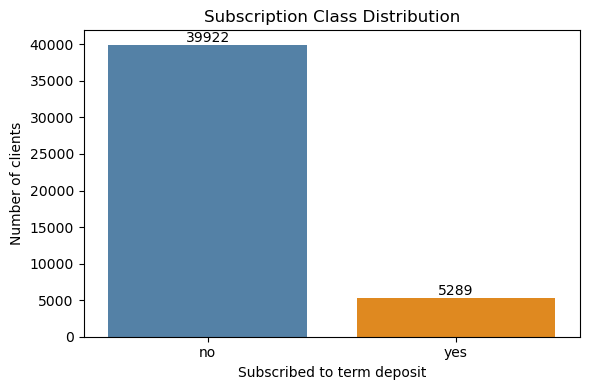

In [4]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x="y", order=["no", "yes"], hue="y", legend=False, ax=ax, palette=["steelblue", "darkorange"])
ax.set_title("Subscription Class Distribution")
ax.set_xlabel("Subscribed to term deposit")
ax.set_ylabel("Number of clients")
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")
plt.tight_layout()
plt.show()


The plot shows a substantial class imbalance: 39,922 clients did not subscribe, compared with 5,289 who did. This 7.5-to-1 ratio is the baseline for interpreting precision and PR-AUC later; a useful model must rank subscribers above the 11.7% positive-class baseline.

# 2) Data Quality and Comprehensive EDA

## Task 2.1 Inspect data types, missing values, duplicates, and ranges

In [5]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


In [6]:
quality_summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique()
})
quality_summary


,dtype,missing_count,missing_percent,unique_values
age,int64,0,0.0,77
job,str,0,0.0,12
marital,str,0,0.0,3
education,str,0,0.0,4
default,str,0,0.0,2
balance,int64,0,0.0,7168
housing,str,0,0.0,2
loan,str,0,0.0,2
contact,str,0,0.0,3
day,int64,0,0.0,31


The audit shows all 45,211 rows are complete and every field has a recorded value. The “unknown” entries in fields such as contact and poutcome are dataset categories, not nulls; retaining them preserves information about records where that history was unavailable.

In [7]:
print(f"Exact duplicate rows: {df.duplicated().sum():,}")
print("Numeric summary:")
display(df.describe().T.round(2))
print("Categorical summary:")
display(df.select_dtypes(exclude=np.number).describe().T)


Exact duplicate rows: 0
Numeric summary:


,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.94,10.62,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.27,3044.77,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.81,8.32,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.16,257.53,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.76,3.10,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.20,100.13,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.58,2.30,0.0,0.0,0.0,0.0,275.0


Categorical summary:


,count,unique,top,freq
job,45211,12,blue-collar,9732
marital,45211,3,married,27214
education,45211,4,secondary,23202
default,45211,2,no,44396
housing,45211,2,yes,25130
loan,45211,2,no,37967
contact,45211,3,cellular,29285
month,45211,12,may,13766
poutcome,45211,4,unknown,36959
y,45211,2,no,39922


The file contains 45,211 clients, 16 candidate predictors, and one outcome. There are no missing values or exact duplicate rows, so no imputation or duplicate removal is needed.

In the campaign history, pdays = -1 encodes no prior contact. It is a status code rather than an elapsed time, so we add a separate indicator before modeling while retaining pdays to represent recency for clients who were contacted.

## Task 2.2 Explore numerical features

In [8]:
target_numeric = df["y"].map({"no": 0, "yes": 1})
numeric_features_all = df.select_dtypes(include=np.number).columns.tolist()

numeric_summary = df[numeric_features_all].describe().T
numeric_summary["IQR"] = numeric_summary["75%"] - numeric_summary["25%"]
numeric_summary["skew"] = df[numeric_features_all].skew()
numeric_summary.round(2)


,count,mean,std,min,25%,50%,75%,max,IQR,skew
age,45211.0,40.94,10.62,18.0,33.0,39.0,48.0,95.0,15.0,0.68
balance,45211.0,1362.27,3044.77,-8019.0,72.0,448.0,1428.0,102127.0,1356.0,8.36
day,45211.0,15.81,8.32,1.0,8.0,16.0,21.0,31.0,13.0,0.09
duration,45211.0,258.16,257.53,0.0,103.0,180.0,319.0,4918.0,216.0,3.14
campaign,45211.0,2.76,3.10,1.0,1.0,2.0,3.0,63.0,2.0,4.90
pdays,45211.0,40.20,100.13,-1.0,-1.0,-1.0,-1.0,871.0,0.0,2.62
previous,45211.0,0.58,2.30,0.0,0.0,0.0,0.0,275.0,0.0,41.85


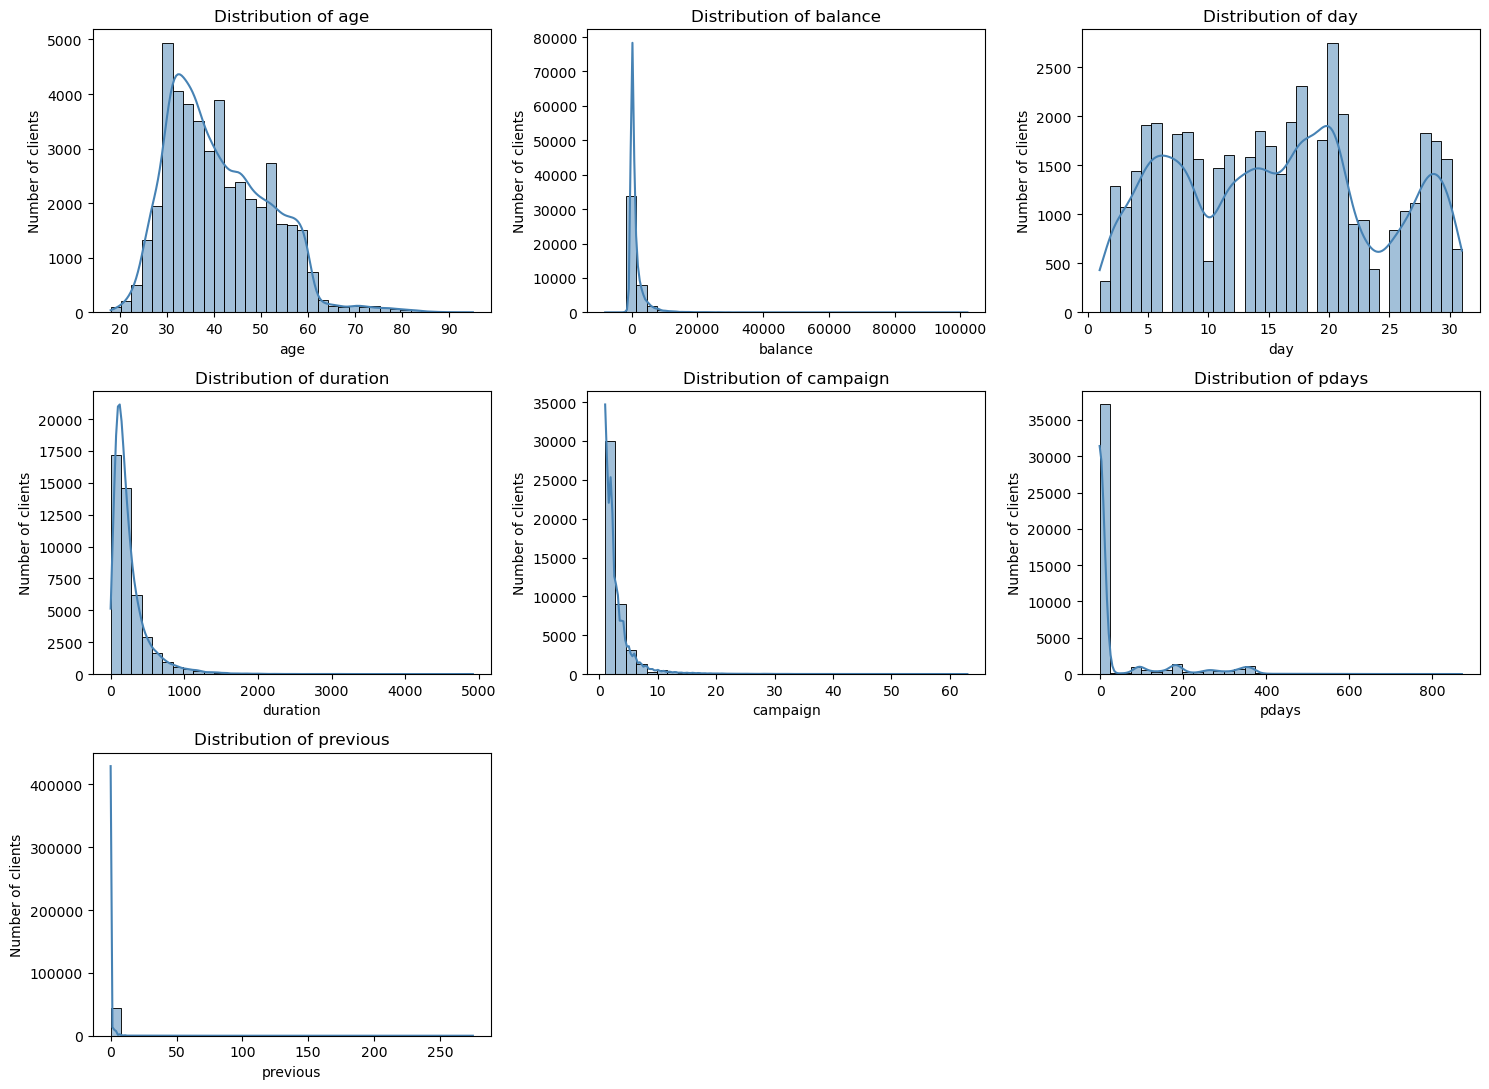

In [9]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, col in zip(axes.flat, numeric_features_all):
    sns.histplot(data=df, x=col, bins=35, kde=True, ax=ax, color="steelblue")
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Number of clients")
for ax in axes.flat[len(numeric_features_all):]:
    ax.axis("off")
plt.tight_layout()
plt.show()


Age and day of month are comparatively concentrated, while balance and call duration have long right tails. Campaign, pdays, and previous are also concentrated near small values: the median previous count is zero, and the 25th, 50th, and 75th percentiles of pdays are all -1. These shapes reflect many clients with little or no prior campaign history and a smaller group with repeated contacts or unusually large values.

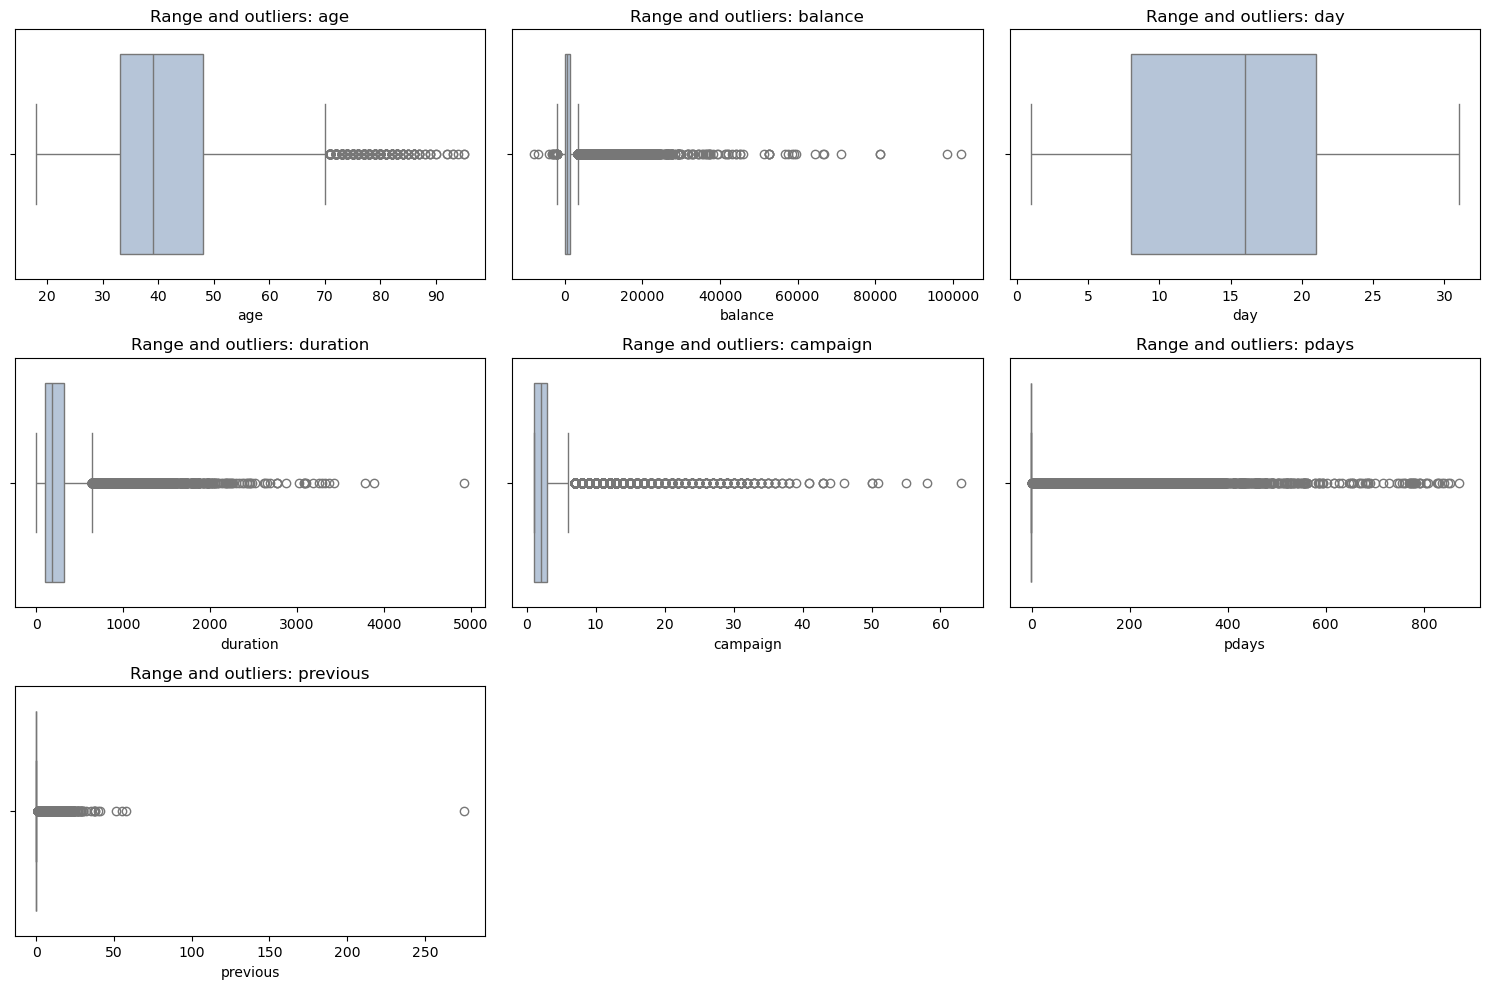

In [10]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, col in zip(axes.flat, numeric_features_all):
    sns.boxplot(data=df, x=col, ax=ax, color="lightsteelblue")
    ax.set_title(f"Range and outliers: {col}")
    ax.set_xlabel(col)
for ax in axes.flat[len(numeric_features_all):]:
    ax.axis("off")
plt.tight_layout()
plt.show()


The boxplots flag long tails rather than obvious data-entry failures: balance reaches 102,127, campaign reaches 63 contacts, and previous reaches 275 prior contacts. These records can represent real customer histories. We retain them and standardize numeric features inside the training pipeline instead of deleting observations based only on an outlier rule.

## Task 2.3 Explore categorical features

In [11]:
categorical_features_all = df.select_dtypes(exclude=np.number).columns.drop("y").tolist()
print(f"Categorical features ({len(categorical_features_all)}): {categorical_features_all}")


Categorical features (9): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


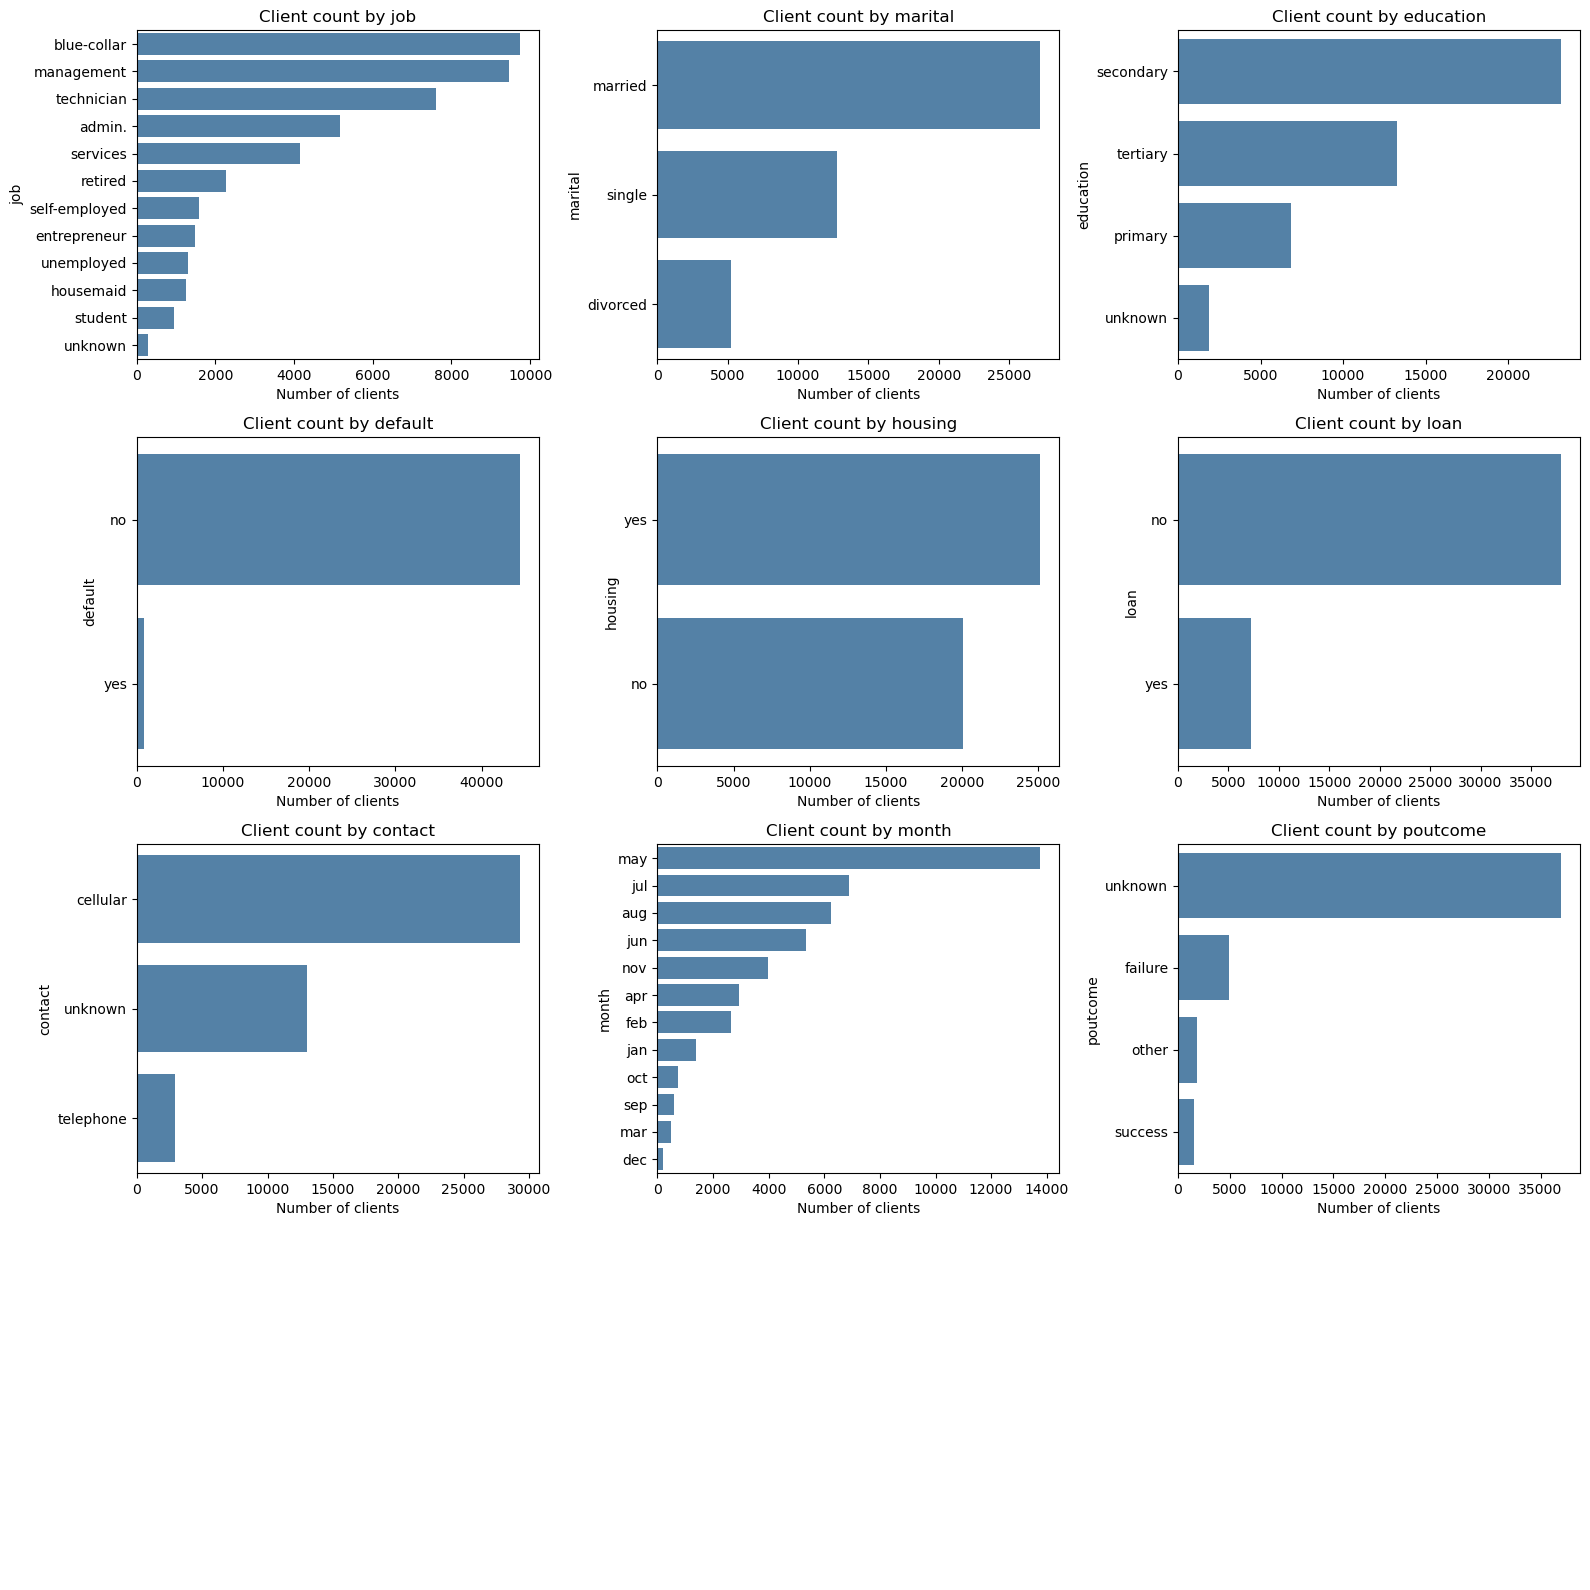

In [12]:
fig, axes = plt.subplots(4, 3, figsize=(16, 16))
for ax, col in zip(axes.flat, categorical_features_all):
    order = df[col].value_counts().index
    sns.countplot(data=df, y=col, order=order, ax=ax, color="steelblue")
    ax.set_title(f"Client count by {col}")
    ax.set_xlabel("Number of clients")
    ax.set_ylabel(col)
for ax in axes.flat[len(categorical_features_all):]:
    ax.axis("off")
plt.tight_layout()
plt.show()


The counts are concentrated in a few groups: blue-collar is the largest job category (9,732 clients), married clients are the largest marital group (27,214), and May is the most common contact month (13,766). Poutcome is “unknown” for 36,959 clients, so later response-rate comparisons for the smaller known-outcome groups should be read alongside their sample sizes.

## Task 2.4 Compare key features with the target

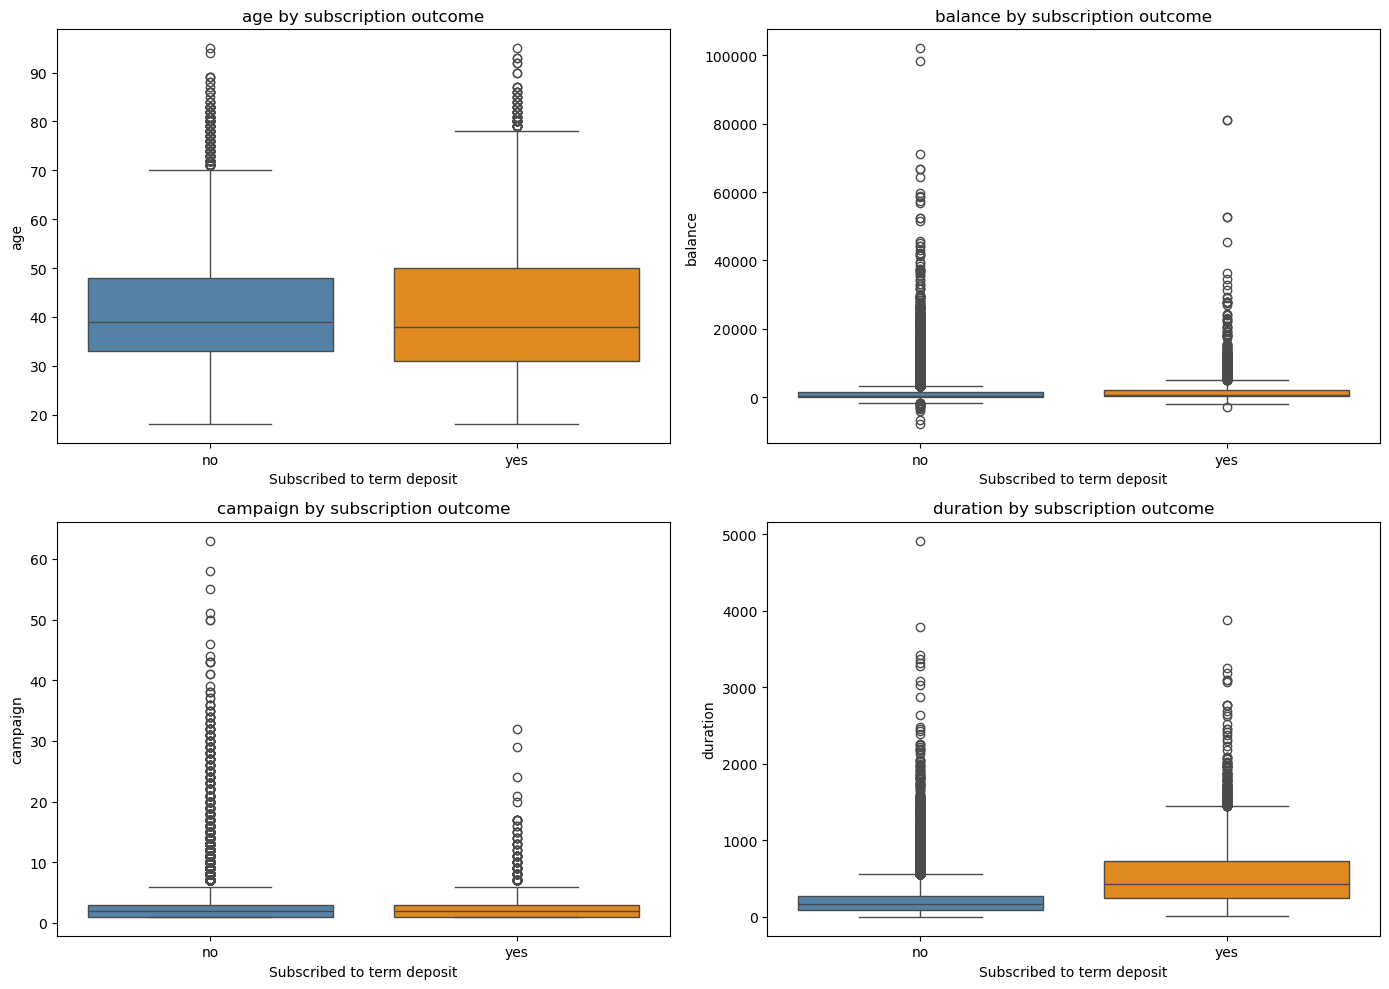

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, col in zip(axes.flat, ["age", "balance", "campaign", "duration"]):
    sns.boxplot(data=df, x="y", y=col, order=["no", "yes"], hue="y", legend=False, ax=ax, palette=["steelblue", "darkorange"])
    ax.set_title(f"{col} by subscription outcome")
    ax.set_xlabel("Subscribed to term deposit")
    ax.set_ylabel(col)
plt.tight_layout()
plt.show()


Age and balance overlap substantially between the two outcomes, so neither boxplot suggests a clean single-feature separation. Median balance is higher among subscribers (733 versus 417), while median campaign count is two in both groups; the mean number of contacts is lower among subscribers (2.1 versus 2.8). Duration separates the groups more strongly (median 426 seconds for subscribers versus 164), but it is only observed after a call and is excluded from pre-call prediction.

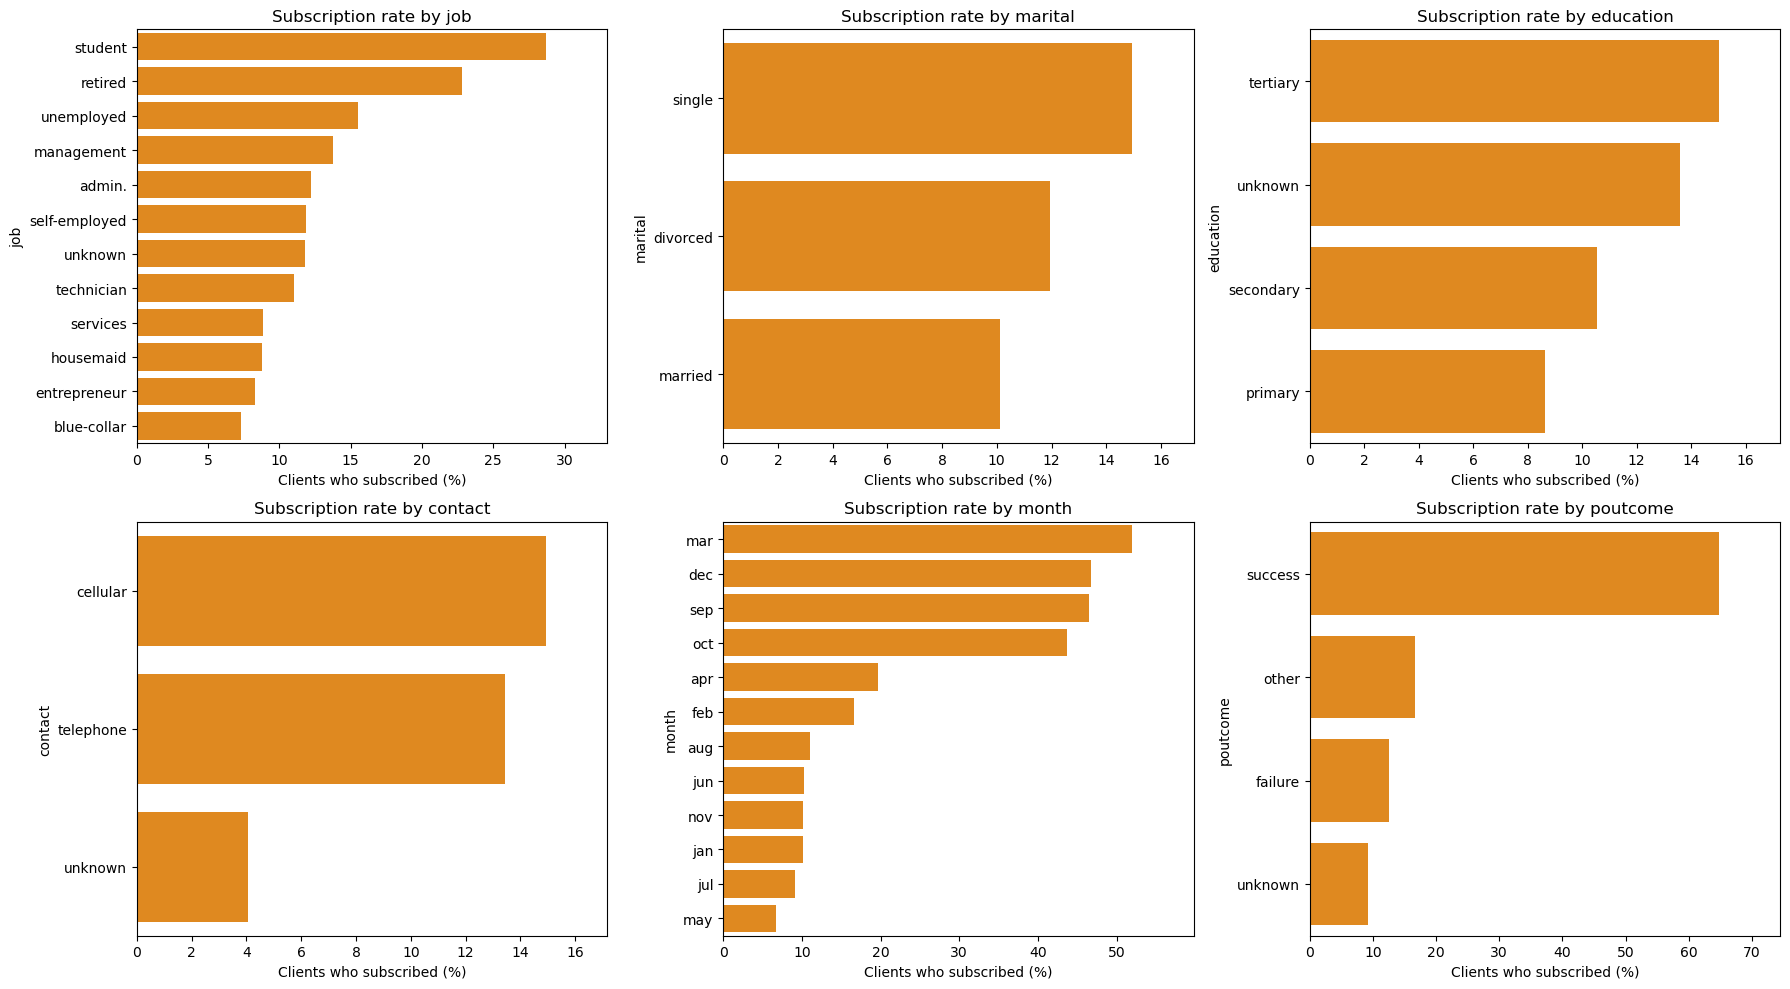

In [14]:
categorical_rate_features = ["job", "marital", "education", "contact", "month", "poutcome"]
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, col in zip(axes.flat, categorical_rate_features):
    rate = df.groupby(col, observed=True)["y"].apply(lambda s: (s == "yes").mean()).sort_values(ascending=False)
    sns.barplot(x=rate.values * 100, y=rate.index, ax=ax, color="darkorange")
    ax.set_title(f"Subscription rate by {col}")
    ax.set_xlabel("Clients who subscribed (%)")
    ax.set_ylabel(col)
    ax.set_xlim(0, max(5, (rate.max() * 100) * 1.15))
plt.tight_layout()
plt.show()


Response rates vary across categories, but sample size changes the strength of the evidence. Students have a 28.7% subscription rate (938 clients) and retirees 22.8% (2,264), while blue-collar clients are at 7.3% (9,732). By month, March is highest at 52.0% but has only 477 clients; May is 6.7% across 13,766 clients. Prior campaign success is strongly associated with a new subscription (64.7%, 1,511 clients), while 9.2% of the much larger unknown-outcome group subscribed. These are descriptive associations, not causal effects.

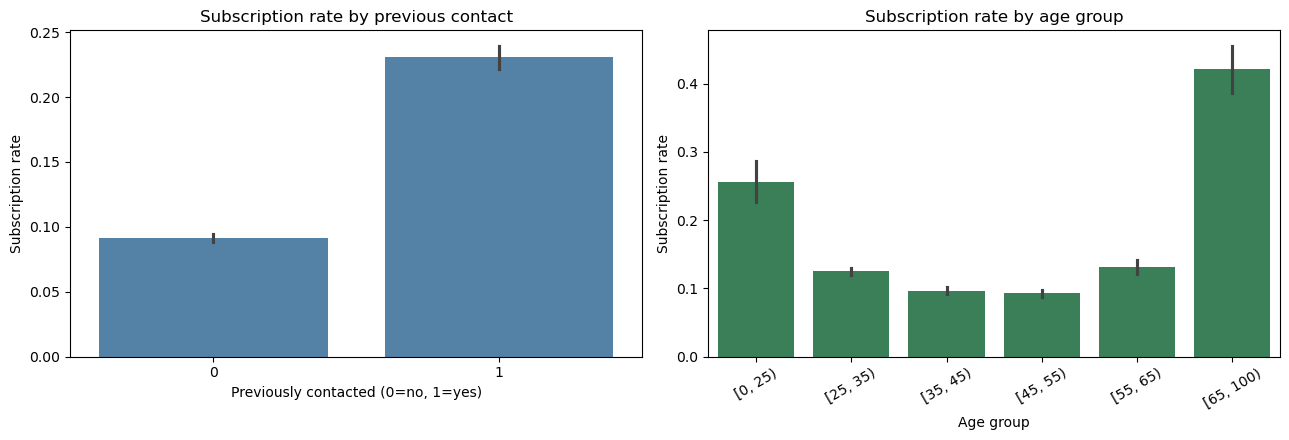

In [15]:
df_eda = df.assign(
    subscribed=target_numeric,
    previously_contacted=(df["pdays"] != -1).astype(int)
)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(data=df_eda, x="previously_contacted", y="subscribed", ax=axes[0], color="steelblue")
axes[0].set_title("Subscription rate by previous contact")
axes[0].set_xlabel("Previously contacted (0=no, 1=yes)")
axes[0].set_ylabel("Subscription rate")
df_eda["age_group"] = pd.cut(df_eda["age"], bins=[0, 25, 35, 45, 55, 65, 100], right=False)
sns.barplot(data=df_eda, x="age_group", y="subscribed", ax=axes[1], color="seagreen")
axes[1].set_title("Subscription rate by age group")
axes[1].set_xlabel("Age group")
axes[1].set_ylabel("Subscription rate")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()


Clients contacted previously had a 23.1% subscription rate versus 9.2% for clients without prior contact. The 65+ age group is also higher (42.1%), but contains only 810 clients; the under-25 group is similarly small (809) and has a 25.6% rate. Rates for age groups 35–55 are about 9–10%. Treat the small-group estimates cautiously: observed differences may be less stable and do not show that age or prior contact causes a subscription.

## Task 2.5 Correlation between numeric variables

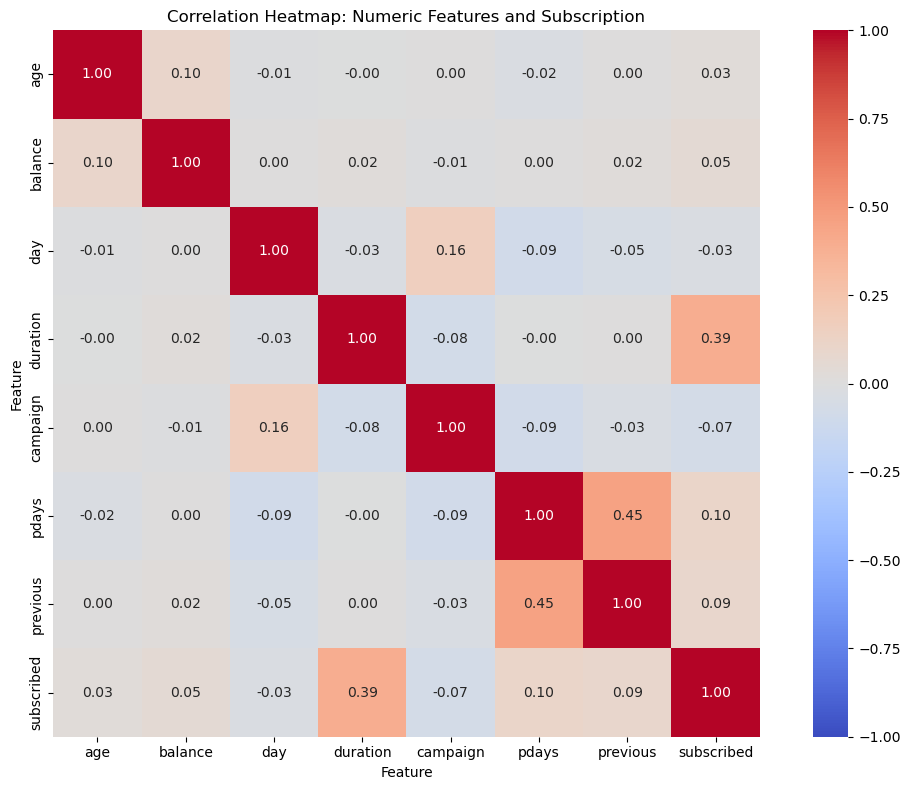

In [16]:
correlation_data = df[numeric_features_all].copy()
correlation_data["subscribed"] = target_numeric
corr_matrix = correlation_data.corr()

plt.figure(figsize=(11, 8))
sns.heatmap(corr_matrix, cmap="coolwarm", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", square=True)
plt.title("Correlation Heatmap: Numeric Features and Subscription")
plt.xlabel("Feature")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [17]:
target_corr = corr_matrix["subscribed"].drop("subscribed").sort_values(key=lambda s: s.abs(), ascending=False)
target_corr.to_frame("Correlation with subscription").round(3)


,Correlation with subscription
duration,0.395
pdays,0.104
previous,0.093
campaign,-0.073
balance,0.053
day,-0.028
age,0.025


Duration has the largest numeric correlation with subscription (0.395), followed by pdays (0.104) and previous contacts (0.093); campaign count is negatively correlated (-0.073). The overall linear associations are modest, and pdays correlation is difficult to interpret because -1 combines all clients never previously contacted. Duration’s stronger relationship is not usable for pre-call prediction because it is only recorded after the call.

# 3) Preprocessing

## Task 3.1 Prepare features and target

In [18]:
# Add a feature with a direct business meaning for the pdays = -1 code.
model_df = df.copy()
model_df["previously_contacted"] = (model_df["pdays"] != -1).astype(int)

# Call duration is excluded because it is only available after the call.
excluded_features = ["y", "duration"]
X = model_df.drop(columns=excluded_features)
y = model_df["y"].map({"no": 0, "yes": 1})

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print(f"Positive class (subscribed=yes): {int(y.sum()):,} ({y.mean():.1%})")
print(f"Features used: {X.shape[1]}")
print(f"Numeric features ({len(numeric_features)}): {numeric_features}")
print(f"Categorical features ({len(categorical_features)}): {categorical_features}")


Positive class (subscribed=yes): 5,289 (11.7%)
Features used: 16
Numeric features (7): ['age', 'balance', 'day', 'campaign', 'pdays', 'previous', 'previously_contacted']
Categorical features (9): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


The positive outcome is encoded as 1 for consistent metric calculation. We add previously_contacted from the pdays sentinel so the model can distinguish “never contacted” from elapsed time among prior contacts. Duration is removed from X because it would not exist at the intended pre-call decision point.

## Task 3.2 Split train/test

In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print(f"Training rows: {len(X_train):,}")
print(f"Test rows: {len(X_test):,}")
print(f"Training subscription rate: {y_train.mean():.3%}")
print(f"Test subscription rate: {y_test.mean():.3%}")


Training rows: 36,168
Test rows: 9,043
Training subscription rate: 11.698%
Test subscription rate: 11.700%


The split contains 36,168 training rows and 9,043 test rows. Stratification preserves the positive rate at 11.7% in both sets, so the test set retains enough subscribers for class-sensitive evaluation while remaining untouched during fitting.

## Task 3.3 Build a preprocessing pipeline

In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ],
    # The encoded dataset is small enough to keep dense for compatibility across models.
    sparse_threshold=0
)

print("Preprocessing steps: standardize numeric columns; one-hot encode categorical columns.")


Preprocessing steps: standardize numeric columns; one-hot encode categorical columns.


Scaling is useful here because balance, age, and campaign history use different ranges, and KNN and SVM depend on feature distances. One-hot encoding keeps nominal categories unordered. Both transformations are fitted within each training pipeline, so the held-out test set does not contribute to preprocessing statistics.

# 4) Train Classification Models

## Task 4.1 Define model candidates

In [21]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from xgboost import XGBClassifier

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1500, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced", min_samples_leaf=10, random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=250, class_weight="balanced_subsample",
        min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE
    ),
    "XGBoost": XGBClassifier(
        n_estimators=300, max_depth=4, learning_rate=0.05,
        subsample=0.85, colsample_bytree=0.85,
        scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
        eval_metric="logloss", tree_method="hist",
        n_jobs=-1, random_state=RANDOM_STATE
    ),
    "KNN": KNeighborsClassifier(n_neighbors=15, weights="distance", n_jobs=-1),
    "SVM (linear)": LinearSVC(
        class_weight="balanced", max_iter=5000, random_state=RANDOM_STATE
    )
}

print("Models to train:")
for name in models:
    print("-", name)


Models to train:
- Logistic Regression
- Decision Tree
- Random Forest
- XGBoost
- KNN
- SVM (linear)


The comparison covers the requested model families: Logistic Regression, Decision Tree, Random Forest, XGBoost, KNN, and a linear SVM. The weighted linear and tree models account for the smaller subscribed class; XGBoost uses scale_pos_weight, while KNN remains unweighted.

## Task 4.2 Fit each pipeline

In [22]:
fitted_models = {}
for name, estimator in models.items():
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", estimator)
    ])
    pipeline.fit(X_train, y_train)
    fitted_models[name] = pipeline

print(f"Fitted {len(fitted_models)} models.")


Fitted 6 models.


All six classifiers use the same split and transformations. Class weighting is applied where supported to make the minority subscription class matter during fitting; KNN has no equivalent class-weight option here, so its recall and precision should be compared directly in the evaluation table.

# 5) Evaluate Models

## Task 5.1 Calculate classification metrics

In [23]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix
)

def get_model_scores(model, X_values):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X_values)[:, 1]
    return model.decision_function(X_values)

model_results = {}
score_values = {}
prediction_values = {}

for name, model in fitted_models.items():
    predictions = model.predict(X_test)
    scores = get_model_scores(model, X_test)
    prediction_values[name] = predictions
    score_values[name] = scores
    model_results[name] = {
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, scores),
        "PR-AUC (Average Precision)": average_precision_score(y_test, scores),
        "Confusion Matrix": confusion_matrix(y_test, predictions, labels=[0, 1])
    }

metrics_table = pd.DataFrame({
    name: {metric: value for metric, value in values.items() if metric != "Confusion Matrix"}
    for name, values in model_results.items()
}).T.sort_values("PR-AUC (Average Precision)", ascending=False)

metrics_table.round(3)


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC (Average Precision)
XGBoost,0.818,0.349,0.644,0.453,0.807,0.471
Random Forest,0.886,0.515,0.396,0.448,0.802,0.449
Logistic Regression,0.755,0.267,0.624,0.374,0.772,0.409
SVM (linear),0.758,0.268,0.619,0.374,0.772,0.405
KNN,0.893,0.649,0.187,0.291,0.738,0.380
Decision Tree,0.736,0.239,0.576,0.338,0.717,0.340


Subscribers make up 11.7% of the test set, so the PR-AUC baseline is approximately 0.117. PR-AUC shows how much each model improves positive-class ranking over that baseline. ROC-AUC gives a broader ranking comparison, while threshold-based precision, recall, and F1 show the practical consequences of each model’s default decision rule.

## Task 5.2 Compare confusion matrices

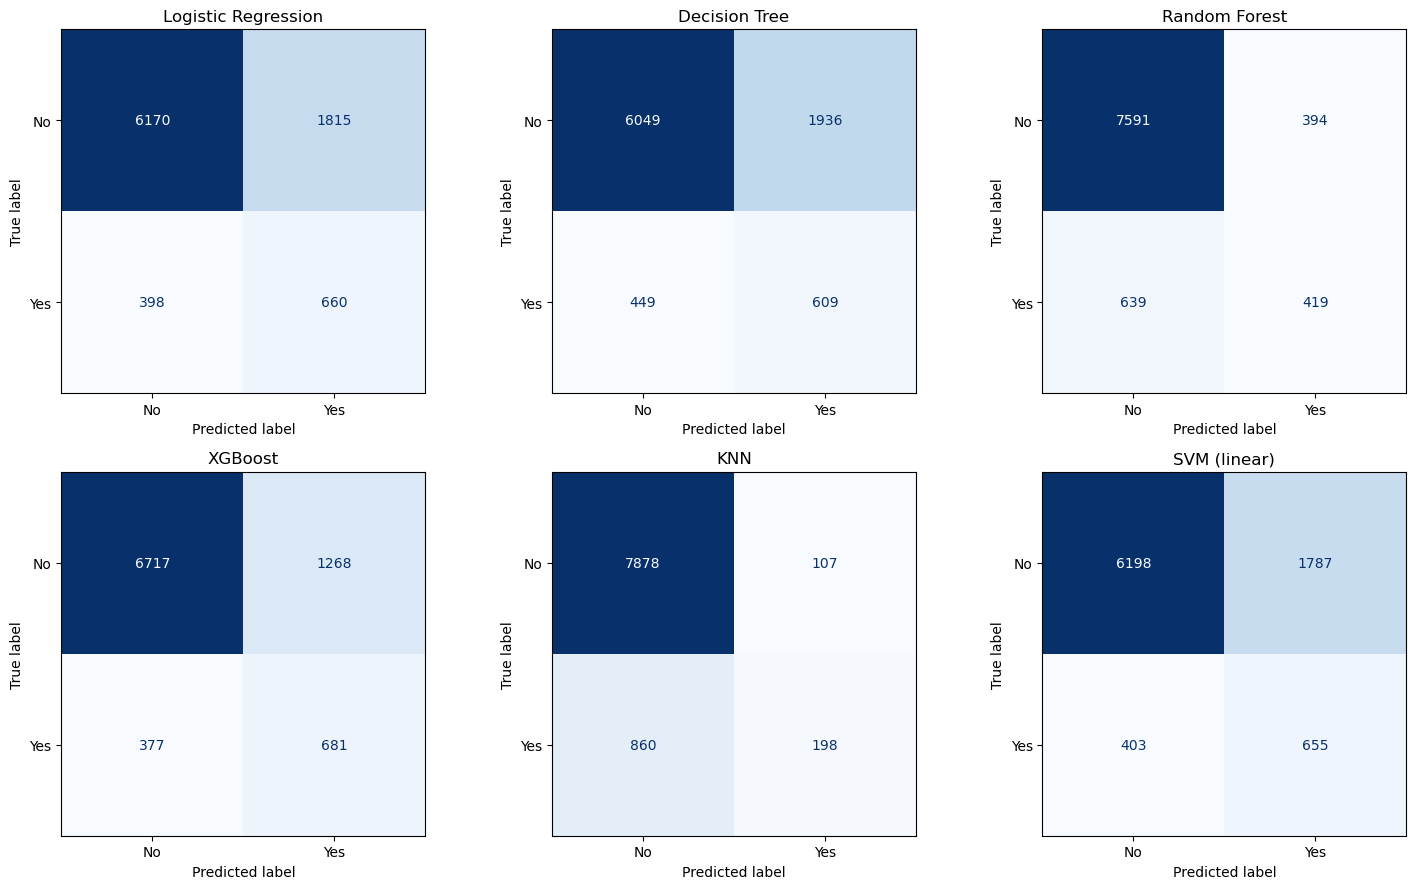

In [24]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (name, predictions) in zip(axes.flat, prediction_values.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions, labels=[0, 1],
        display_labels=["No", "Yes"], cmap="Blues",
        values_format="d", ax=ax, colorbar=False
    )
    ax.set_title(name)
for ax in axes.flat[len(prediction_values):]:
    ax.axis("off")
plt.tight_layout()
plt.show()


For this campaign, false negatives are subscribers the model fails to prioritize; false positives are non-subscribers who still receive outreach. The preferred balance depends on contact capacity and the cost of each call. Compare positive-class recall with the number of false positives rather than choosing a model from accuracy alone.

## Task 5.3 Plot ROC-AUC curves

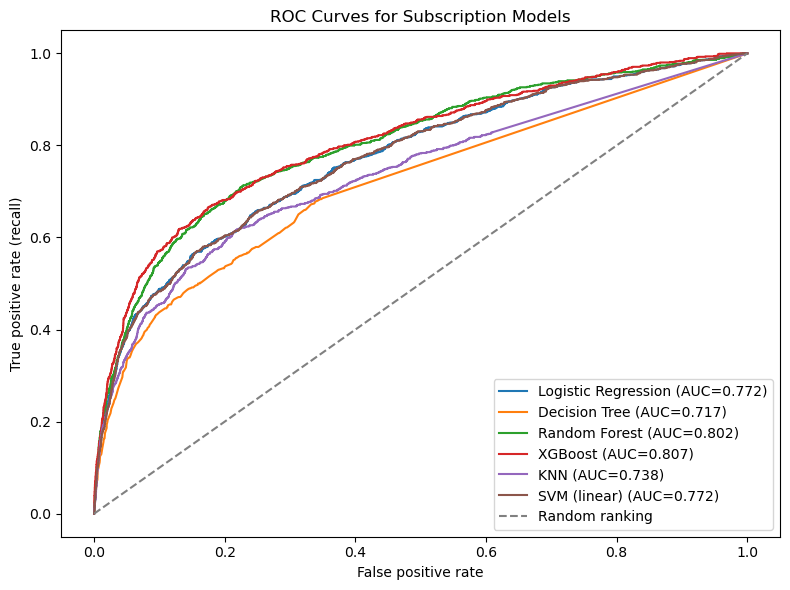

In [25]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(8, 6))
for name, scores in score_values.items():
    fpr, tpr, _ = roc_curve(y_test, scores)
    auc_value = model_results[name]["ROC-AUC"]
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc_value:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random ranking")
plt.title("ROC Curves for Subscription Models")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (recall)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


The diagonal is random ranking. Curves closer to the upper-left identify more subscribers at a given false-positive rate. If two ROC curves are close, use PR-AUC and the campaign’s acceptable false-positive volume to distinguish them; ROC-AUC alone can look favorable when the negative class is much larger.

## Task 5.4 Plot precision-recall curves

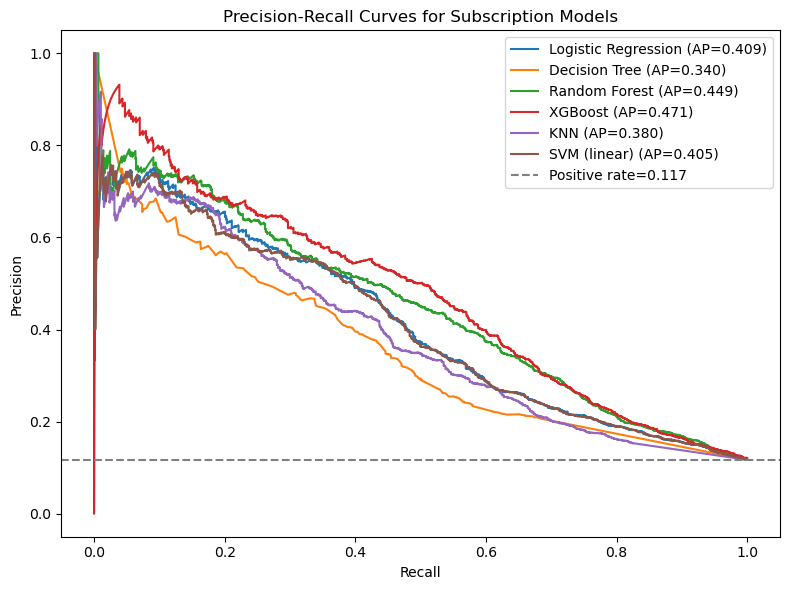

In [26]:
from sklearn.metrics import precision_recall_curve

plt.figure(figsize=(8, 6))
for name, scores in score_values.items():
    precision_values, recall_values, _ = precision_recall_curve(y_test, scores)
    ap_value = model_results[name]["PR-AUC (Average Precision)"]
    plt.plot(recall_values, precision_values, label=f"{name} (AP={ap_value:.3f})")
baseline_rate = y_test.mean()
plt.axhline(baseline_rate, linestyle="--", color="gray", label=f"Positive rate={baseline_rate:.3f}")
plt.title("Precision-Recall Curves for Subscription Models")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend(loc="best")
plt.tight_layout()
plt.show()


The dashed reference is the test-set subscription rate (about 11.7%). Curves above it indicate positive-class ranking better than random selection. The most useful model is the one that maintains practical precision at the recall level the campaign needs, not necessarily the model with highest precision at one extreme cutoff.

# 6) Results Discussion and Summary

## Model comparison and interpretation

In [29]:
comparison = metrics_table.copy()
comparison["Comment"] = [
    "Strongest positive-class ranking in this test comparison." if name == metrics_table.index[0]
    else "Baseline comparison; check precision and recall against campaign capacity."
    for name in comparison.index
]
comparison.round(3)


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC (Average Precision),Comment
XGBoost,0.818,0.349,0.644,0.453,0.807,0.471,Strongest positive-class ranking in this test ...
Random Forest,0.886,0.515,0.396,0.448,0.802,0.449,Baseline comparison; check precision and recal...
Logistic Regression,0.755,0.267,0.624,0.374,0.772,0.409,Baseline comparison; check precision and recal...
SVM (linear),0.758,0.268,0.619,0.374,0.772,0.405,Baseline comparison; check precision and recal...
KNN,0.893,0.649,0.187,0.291,0.738,0.380,Baseline comparison; check precision and recal...
Decision Tree,0.736,0.239,0.576,0.338,0.717,0.340,Baseline comparison; check precision and recal...


XGBoost leads the test-set comparison on ROC-AUC (0.807) and PR-AUC (0.471), with recall 0.644 and F1 0.453 at its default cutoff. Random Forest has higher precision (0.515) and a similar F1 (0.448), while KNN has the highest accuracy (0.893) but finds only 18.7% of subscribers. The best choice depends on whether the campaign values broader subscriber coverage or a more selective contact list.

## Summary

- The dataset contains 45,211 clients; 11.7% subscribed. There are no missing values or exact duplicate rows.
- Response rates differ across campaign history, month, job, and age groups. High rates in small groups should be interpreted alongside their sample sizes.
- Duration is strongly associated with subscription but is excluded because it is unavailable before a call. Numeric fields are standardized and categorical fields are one-hot encoded inside the training pipelines.
- XGBoost has the strongest test-set ranking in this run: ROC-AUC 0.807 and PR-AUC 0.471, compared with the 0.117 positive-class baseline. At its default cutoff, recall is 0.644, precision 0.349, and F1 0.453. Random Forest is more selective (precision 0.515, recall 0.396); KNN has the highest accuracy (0.893) but recalls only 0.187 of subscribers.
- The model comparison uses the test-set results to identify the leading model, so these values are useful for this assignment’s comparison but are not an independent final performance estimate. A production evaluation would select the model using validation data and evaluate the final choice once on untouched test data.